# Fase 4: Pemetaan Spasial & Kesimpulan Akhir

Langkah paripurna dari proyek ini adalah memproyeksikan hasil pengelompokan (clustering) ke dalam peta geografis interaktif maupun statis. Visualisasi spasial sangat penting karena:
- **Analisis Kedekatan**: Kita bisa melihat apakah daerah yang berdekatan secara fisik memiliki pola polusi yang identik.
- **Deteksi Regional**: Memudahkan pemangku kebijakan untuk menetapkan zona merah muda/kuning/merah dalam satu kawasan (misal pesisir utara Jawa Timur).

Karena dataset kita hanya berupa teks nama daerah (tanpa *latitude* dan *longitude*), kita akan menggunakan teknik **Geocoding**.

---
## 4.1 Inisiasi Library & Pengambilan Rekam Jejak
Menggabungkan matriks dari Tahap 2 dan konfigurasi juara dari Tahap 3.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import time
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import folium
from folium.plugins import MiniMap
from sklearn.cluster import KMeans

# Setelan Estetika Visual
sns.set_theme(style='white', font_scale=1.0)
plt.rcParams['figure.figsize'] = (12, 6)

LOKASI_INPUT_T2 = '../data/hasil_tahap2/koleksi_data_tahap2.pkl'
LOKASI_INPUT_T3 = '../data/hasil_tahap3/paket_tahap3.pkl'
DIR_FINAL = '../data/hasil_tahap4'
os.makedirs(DIR_FINAL, exist_ok=True)

# ─── Load Artifacts ──────────────────────────────────────────────
with open(LOKASI_INPUT_T2, 'rb') as f2:
    paket_t2 = pickle.load(f2)
    kumpulan_matriks = paket_t2['koleksi_matriks']
    meta_lin = paket_t2['metadata_lin']
    meta_pol = paket_t2['metadata_pol']
    df_mentah_lin = paket_t2['dataframe_asli_lin']
    df_mentah_pol = paket_t2['dataframe_asli_pol']

with open(LOKASI_INPUT_T3, 'rb') as f3:
    paket_t3 = pickle.load(f3)
    JUARA_DATASET = paket_t3['Dataset_Andalan']
    JUARA_K = paket_t3['K_Andalan']
    JUARA_SIL = paket_t3['Sil_Andalan']
    
    # Konversi palet warna dari RGB tuple (Seaborn) ke Hex String (untuk Folium/HTML)
    import matplotlib.colors as mcolors
    WARNAPALET = [mcolors.to_hex(c) for c in paket_t3['Palet_Warna']]
    
    rekap_keseluruhan = paket_t3['Rekap_Evaluasi']

# Kita perlu merekonstruksi label untuk pemenang di setiap dimensi
daftar_kunci_dimensi = ['Linier_Asli_204', 'Linier_Fase1_203', 'Linier_Fase2_74', 'Linier_Fase3_37',
                        'Polinom_Asli_204', 'Polinom_Fase1_203', 'Polinom_Fase2_74', 'Polinom_Fase3_37']

koleksi_konfigurasi_pemenang = {}
print("Mengekstrak ulang label pemenang untuk masing-masing dimensi...")

for dk in daftar_kunci_dimensi:
    # Cari nilai K terbaik dari rekapan
    df_filter = rekap_keseluruhan[rekap_keseluruhan['Entitas_Data'] == dk]
    k_terbaik = int(df_filter.loc[df_filter['Skor_Silhouette'].idxmax(), 'Nilai_K'])
    sil_terbaik = df_filter['Skor_Silhouette'].max()
    
    # Jalankan KMeans ulang untuk mendapatkan label
    km_model = KMeans(n_clusters=k_terbaik, n_init=20, random_state=42)
    matriks_x = kumpulan_matriks[dk]
    label_mentah = km_model.fit_predict(matriks_x)
    
    # Urutkan label agar 0 selalu yang paling banyak (konsisten dengan tahap 3)
    dist = np.bincount(label_mentah, minlength=k_terbaik)
    urut = np.argsort(-dist, kind='stable')
    peta_konversi = np.empty(k_terbaik, dtype=int)
    peta_konversi[urut] = np.arange(k_terbaik)
    label_final = peta_konversi[label_mentah]
    
    koleksi_konfigurasi_pemenang[dk] = {
        'k': k_terbaik,
        'sil': sil_terbaik,
        'labels': label_final,
        'populasi': np.bincount(label_final, minlength=k_terbaik).tolist()
    }
    
    tanda = "🌟 (GLOBAL)" if dk == JUARA_DATASET else "✓"
    print(f" {tanda} {dk:<18} -> k={k_terbaik}, sil={sil_terbaik:.4f}")

# Override palet warna agar mengakomodasi jumlah K tertinggi dari semua model (k=3)
MAX_K = max(kfg['k'] for kfg in koleksi_konfigurasi_pemenang.values())
WARNAPALET_BARU = sns.color_palette("Set1", MAX_K)
WARNAPALET = [mcolors.to_hex(c) for c in WARNAPALET_BARU]



Mengekstrak ulang label pemenang untuk masing-masing dimensi...
 ✓ Linier_Asli_204    -> k=2, sil=0.4909
 ✓ Linier_Fase1_203   -> k=2, sil=0.4909
 ✓ Linier_Fase2_74    -> k=2, sil=0.4021
 ✓ Linier_Fase3_37    -> k=2, sil=0.4021
 🌟 (GLOBAL) Polinom_Asli_204   -> k=2, sil=0.5375
 ✓ Polinom_Fase1_203  -> k=2, sil=0.5375
 ✓ Polinom_Fase2_74   -> k=3, sil=0.4543
 ✓ Polinom_Fase3_37   -> k=3, sil=0.4543


## 4.2 Mesin Pencari Koordinat (Geocoding)

Kita menggunakan kamus koordinat manual untuk daerah-daerah yang rawan meleset jika diserahkan sepenuhnya ke mesin otomatis (seperti Nominatim). Titik *fallback* diletakkan di koordinat nol (-7.5, 112.7).


In [2]:
REFERENSI_TITIK_AKURAT = {
    'Baron Nganjuk': (-7.5083, 111.9167),
    'Nunukan': (4.1333, 117.6667),
    'Sreseh, Sampang': (-7.1833, 113.2167),
    'Manyar, Gresik': (-7.1500, 112.6500),
    'Kamal, Bangkalan': (-7.1833, 112.7833),
    'Kedungpring Lamongan': (-7.3500, 112.2167),
    'Gresik Kota, Gresik': (-7.1556, 112.6527),
    'Waru, Pamekasan': (-7.1667, 113.4833),
    'Paciran, Lamongan': (-6.8667, 112.3333),
    'Kertosono, Nganjuk': (-7.5833, 112.1000),
    'Banyu Ajuh, Perumnas, Kamal': (-7.1833, 112.7833),
    'Banyuajuh kamal, Bangkalan': (-7.1833, 112.7833),
    'Bandung - Jogoroto, Jombang': (-7.5467, 112.2331),
    'Kec. Kalianget, Sumenep': (-7.0583, 113.9333),
    'Jabon, Sidoarjo': (-7.5351, 112.8106),
    'Sidoarjo, Wonoayu': (-7.4455, 112.6644),
    'Jabon , Sidoarjo': (-7.5351, 112.8106),
}

TITIK_CADANGAN = (-7.5000, 112.7000)
FILE_MEMORI = os.path.join(DIR_FINAL, 'memori_koordinat.json')

if os.path.exists(FILE_MEMORI):
    with open(FILE_MEMORI, 'r') as fm:
        memori_koordinat = json.load(fm)
    print(f"-> Memori diload: {len(memori_koordinat)} data.")
else:
    memori_koordinat = {}

# Suntik manual
for d, k in REFERENSI_TITIK_AKURAT.items():
    memori_koordinat[d] = list(k)

def ekstraksi_titik(nama_daerah):
    if nama_daerah in memori_koordinat:
        return tuple(memori_koordinat[nama_daerah])
    
    # Cari kemiripan di kamus manual
    for kunci_man, koor_man in REFERENSI_TITIK_AKURAT.items():
        if nama_daerah.lower() in kunci_man.lower() or kunci_man.lower() in nama_daerah.lower():
            return koor_man
            
    # Autocari via geopy
    try:
        from geopy.geocoders import Nominatim
        pelacak = Nominatim(user_agent='eksplorasi_psd_agent')
        hasil = pelacak.geocode(nama_daerah + ", Indonesia")
        if hasil:
            print(f" [Nominatim] {nama_daerah} ketemu di {hasil.latitude}, {hasil.longitude}")
            return (hasil.latitude, hasil.longitude)
    except Exception as er:
        pass
        
    return TITIK_CADANGAN

himpunan_wilayah = set(meta_lin['daerah'].tolist() + meta_pol['daerah'].tolist())
for wil in himpunan_wilayah:
    if wil not in memori_koordinat:
        t_baru = ekstraksi_titik(wil)
        memori_koordinat[wil] = [t_baru[0], t_baru[1]]
        time.sleep(0.2)

# Simpan
with open(FILE_MEMORI, 'w') as fm:
    json.dump(memori_koordinat, fm)
    
print(f"\nGeocoding tuntas. Total memori koordinat: {len(memori_koordinat)}")


-> Memori diload: 36 data.

Geocoding tuntas. Total memori koordinat: 36


## 4.3 Penyusunan Kerangka Peta (GeoDataFrame)

Membentuk tabel gabungan yang berisi metadata daerah, koordinat spasial, label cluster, dan konsentrasi polutan utama (NO2, SO2, CO) sebagai referensi *tooltip/popup*.


In [3]:
wadah_df_peta = {}

for id_dim, isi in koleksi_konfigurasi_pemenang.items():
    sumber_meta = meta_lin.copy() if 'Linier' in id_dim else meta_pol.copy()
    sumber_raw = df_mentah_lin if 'Linier' in id_dim else df_mentah_pol
    
    sumber_meta['ID_Cluster'] = isi['labels']
    sumber_meta['Lintang'] = sumber_meta['daerah'].map(lambda d: memori_koordinat.get(d, TITIK_CADANGAN)[0])
    sumber_meta['Bujur'] = sumber_meta['daerah'].map(lambda d: memori_koordinat.get(d, TITIK_CADANGAN)[1])
    
    # Sisipkan nilai rata-rata zat untuk tooltip
    for zat in ['no2', 'so2', 'co']:
        kol = f'{zat}_calc_mean'
        sumber_meta[f'{zat}_Rata2'] = sumber_raw[kol].values if kol in sumber_raw.columns else np.nan
        
    wadah_df_peta[id_dim] = sumber_meta

df_peta_utama = wadah_df_peta[JUARA_DATASET]

print(f"Pratinjau Data Spasial untuk Konfigurasi Tertinggi ({JUARA_DATASET}):")
display(df_peta_utama[['daerah', 'ID_Cluster', 'Lintang', 'Bujur', 'no2_Rata2', 'so2_Rata2', 'co_Rata2']].head())


Pratinjau Data Spasial untuk Konfigurasi Tertinggi (Polinom_Asli_204):


,daerah,ID_Cluster,Lintang,Bujur,no2_Rata2,so2_Rata2,co_Rata2
0,Baron Nganjuk,0,-7.5083,111.9167,0.000028,0.000072,0.030248
1,Nunukan,0,4.1333,117.6667,0.000007,-0.000005,0.027691
2,"Sreseh, Sampang",0,-7.1833,113.2167,0.000027,0.000007,0.029516
3,"Manyar, Gresik",0,-7.1500,112.6500,0.000071,0.000161,0.028816
4,"Kamal, Bangkalan",0,-7.1833,112.7833,0.000083,0.000140,0.027027


## 4.4 Pembuatan Peta Dinamis (Folium)

Fitur Peta:
1. Menggunakan basemap murni yang tidak membutuhkan kunci API (OpenStreetMap & CartoDB Positron format alternatif).
2. *Layer Control* untuk mengaktifkan matikan tampilan dari ke-8 konfigurasi (204 s.d 37).
3. Modul antarmuka Popup yang rapi dengan indikator numerik polutan.


In [4]:
peta_utama = folium.Map(
    location=[-5.0, 115.0], 
    zoom_start=6,
    tiles=None,
    control_scale=True
)

folium.TileLayer('OpenStreetMap', name='Standar (OSM)', show=True).add_to(peta_utama)
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Tiles &copy; Esri',
    name='Esri Navigasi', show=False
).add_to(peta_utama)
folium.TileLayer(
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}',
    attr='Esri Satelit',
    name='Citra Satelit', show=False
).add_to(peta_utama)

def rakit_layer_folium(objek_peta, df_wilayah, nama_id, properti):
    aktif = (nama_id == JUARA_DATASET)
    nama_kontrol = f"{nama_id} | k={properti['k']}, Sil={properti['sil']:.3f}"
    if aktif: nama_kontrol += " 🌟"
    
    grup_lapisan = folium.FeatureGroup(name=nama_kontrol, show=aktif)
    
    for _, baris in df_wilayah.iterrows():
        id_c = int(baris['ID_Cluster'])
        warna_c = WARNAPALET[id_c % len(WARNAPALET)]
        
        n_txt = f"{baris['no2_Rata2']:.5f}" if pd.notna(baris.get('no2_Rata2')) else '-'
        s_txt = f"{baris['so2_Rata2']:.5f}" if pd.notna(baris.get('so2_Rata2')) else '-'
        c_txt = f"{baris['co_Rata2']:.5f}" if pd.notna(baris.get('co_Rata2')) else '-'
        
        # Desain HTML Popup Custom
        html_desain = f"""
        <div style="font-family: Arial; width: 230px;">
            <div style="background:{warna_c}; color:white; padding: 6px; border-radius: 4px 4px 0 0;">
                <h4 style="margin:0; font-size:14px;">Cluster {id_c}</h4>
            </div>
            <div style="border: 1px solid #ccc; padding: 10px; background:#f9f9f9;">
                <b>{baris['daerah']}</b><br>
                <small style="color:gray;">{baris['Lintang']:.3f}, {baris['Bujur']:.3f}</small>
                <hr style="margin:5px 0;">
                <table style="width:100%; font-size:12px;">
                    <tr><td style="color:blue;">NO₂</td><td>: {n_txt}</td></tr>
                    <tr><td style="color:red;">SO₂</td><td>: {s_txt}</td></tr>
                    <tr><td style="color:green;">CO</td><td>: {c_txt}</td></tr>
                </table>
            </div>
        </div>
        """
        
        folium.CircleMarker(
            location=[baris['Lintang'], baris['Bujur']],
            radius=12, fill=True, color=warna_c,
            fill_color=warna_c, fill_opacity=0.8, weight=1,
            popup=folium.Popup(html_desain, max_width=300),
            tooltip=f"{baris['daerah']} (Cluster {id_c})"
        ).add_to(grup_lapisan)
        
        # Angka di dalam lingkaran
        folium.Marker(
            location=[baris['Lintang'], baris['Bujur']],
            icon=folium.DivIcon(html=f"<div style='font-size:10px; color:white; font-weight:bold; text-align:center; margin-top:2px;'>C{id_c}</div>"),
            interactive=False
        ).add_to(grup_lapisan)
        
    grup_lapisan.add_to(objek_peta)

# Pasang ke-8 layer
for id_d, konfigurasi in koleksi_konfigurasi_pemenang.items():
    rakit_layer_folium(peta_utama, wadah_df_peta[id_d], id_d, konfigurasi)

# Panel Legenda Custom HTML
tabel_l = ""
for id_d, kfg in koleksi_konfigurasi_pemenang.items():
    bintang = '⭐' if id_d == JUARA_DATASET else ''
    ukr = " - ".join(map(str, kfg['populasi']))
    tabel_l += f"<tr><td style='padding:2px 5px;'><b>{id_d}</b> {bintang}</td><td style='padding:2px 5px;'>{kfg['k']}</td><td style='padding:2px 5px;'>{kfg['sil']:.3f}</td><td style='padding:2px 5px;'>{ukr}</td></tr>"

elemen_warna = ""
for i in range(MAX_K):
    elemen_warna += f"<span style='display:inline-block; margin-right:10px;'><span style='background:{WARNAPALET[i]}; width:15px; height:15px; display:inline-block; border-radius:50%; vertical-align:middle;'></span> C{i}</span>"

desain_legenda = f"""
<div style="position:fixed; bottom:20px; left:20px; z-index:999; background:white; padding:15px; border-radius:8px; box-shadow: 2px 2px 10px rgba(0,0,0,0.3); font-family:sans-serif; font-size:12px;">
    <b style="font-size:14px; color:#2c3e50;">Navigasi Model Clustering</b><br>
    <span style="color:#7f8c8d;">Gunakan kotak lapisan di kanan atas untuk ganti dimensi.</span><br><br>
    <table border="1" style="border-collapse: collapse; text-align:center; border-color:#bdc3c7;">
        <tr style="background:#ecf0f1;"><th>Representasi</th><th>K</th><th>Sil.</th><th>Distribusi</th></tr>
        {tabel_l}
    </table>
    <br>
    <b>Warna Global:</b><br>{elemen_warna}
</div>
"""
peta_utama.get_root().html.add_child(folium.Element(desain_legenda))

folium.LayerControl(collapsed=False).add_to(peta_utama)
MiniMap(toggle_display=True).add_to(peta_utama)

jalur_html = os.path.join(DIR_FINAL, 'Peta_Satelit_Interaktif.html')
peta_utama.save(jalur_html)
print(f"✅ Peta interaktif berhasil dikompilasi di: {jalur_html}")

peta_utama


✅ Peta interaktif berhasil dikompilasi di: ../data/hasil_tahap4\Peta_Satelit_Interaktif.html


## 4.5 Rendering Peta Gambar Statis (Untuk Lampiran Makalah)

Versi Matplotlib yang statis dan siap disalin ke Microsoft Word / PDF Laporan.


findfont: Failed to find font weight heavy, now using 700.
findfont: Failed to find font weight medium, now using 400.


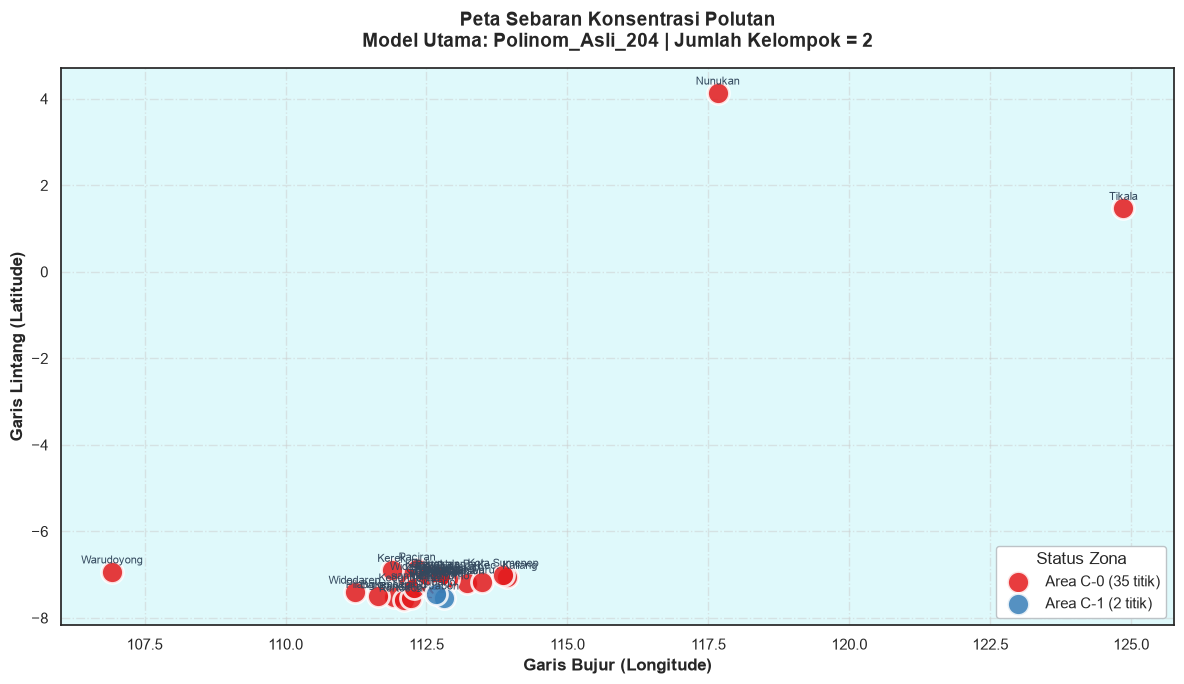

✅ Peta cetak tersimpan di: ../data/hasil_tahap4\Plot_Peta_Statis_Utama.png


In [5]:
fig, ruang = plt.subplots(figsize=(12, 7))

for c_idx in range(JUARA_K):
    filter_data = df_peta_utama[df_peta_utama['ID_Cluster'] == c_idx]
    ruang.scatter(filter_data['Bujur'], filter_data['Lintang'],
                  s=250, color=WARNAPALET[c_idx], edgecolors='white', 
                  linewidth=2, label=f'Area C-{c_idx} ({len(filter_data)} titik)',
                  alpha=0.85, zorder=3)
    
    # Tempel teks lokasi
    for _, brs in filter_data.iterrows():
        teks_pendek = brs['daerah'].split(',')[0][:12]
        ruang.annotate(teks_pendek, xy=(brs['Bujur'], brs['Lintang']),
                       xytext=(0, 6), textcoords='offset points', ha='center',
                       fontsize=8, fontweight='medium', color='#34495e')

ruang.set_facecolor('#dff9fb')
ruang.grid(True, linestyle='-.', alpha=0.5, zorder=0)

ruang.set_xlabel('Garis Bujur (Longitude)', fontweight='bold')
ruang.set_ylabel('Garis Lintang (Latitude)', fontweight='bold')
ruang.set_title(f'Peta Sebaran Konsentrasi Polutan\nModel Utama: {JUARA_DATASET} | Jumlah Kelompok = {JUARA_K}',
                fontsize=14, fontweight='heavy', pad=15)
ruang.legend(loc='lower right', framealpha=1, edgecolor='#bdc3c7', title='Status Zona')

plt.tight_layout()
jalur_png = os.path.join(DIR_FINAL, 'Plot_Peta_Statis_Utama.png')
plt.savefig(jalur_png, dpi=150)
plt.show()
print(f"✅ Peta cetak tersimpan di: {jalur_png}")


### Peta Statis Komparatif (Evolusi Antar Dimensi)
Grid matriks untuk membandingkan pergeseran titik saat fitur direduksi.


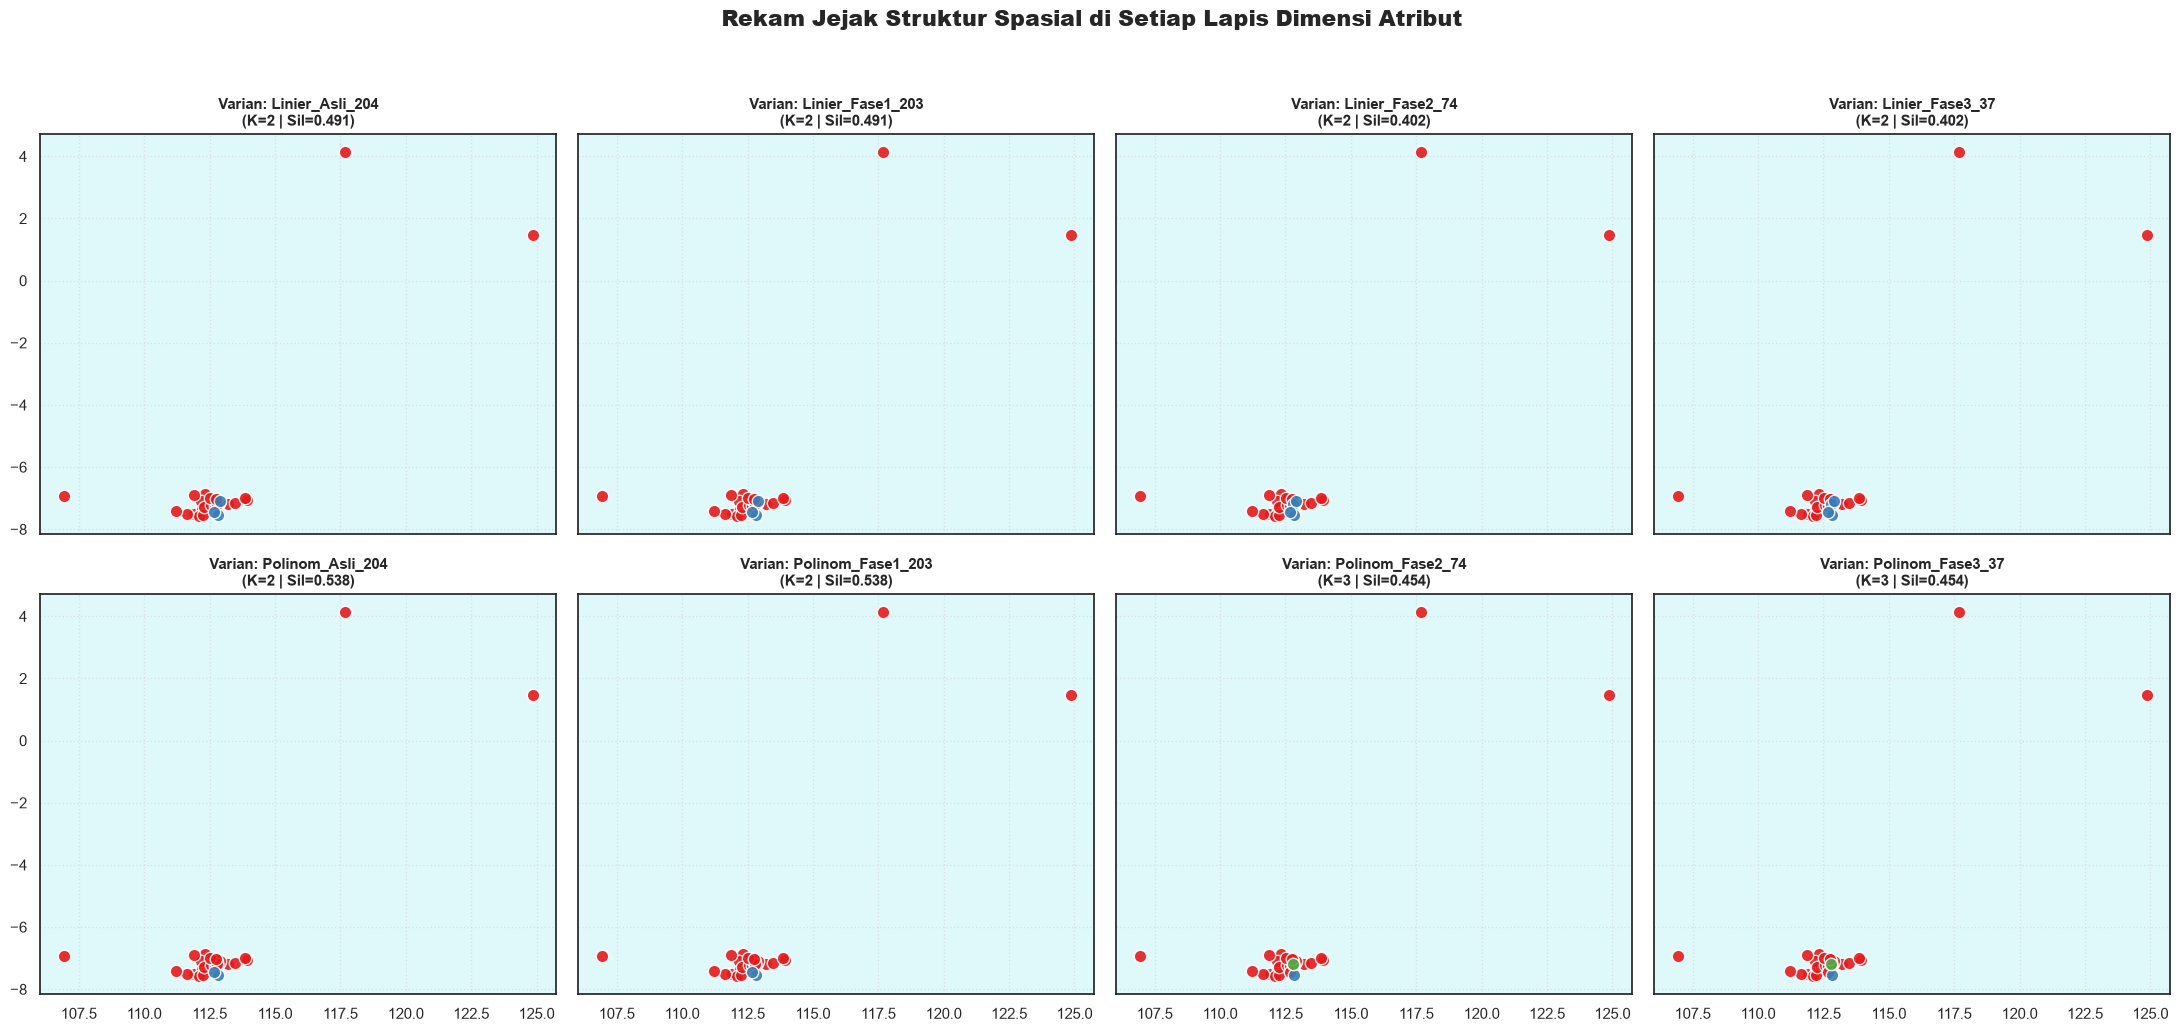

✅ Matriks peta cetak tersimpan di: ../data/hasil_tahap4\Plot_Peta_Komparasi_Dimensi.png


In [6]:
fig, kisi_kisi = plt.subplots(2, 4, figsize=(22, 10), sharex=True, sharey=True)
kisi_linear = kisi_kisi[0]
kisi_polinom = kisi_kisi[1]

alur_lin = ['Linier_Asli_204', 'Linier_Fase1_203', 'Linier_Fase2_74', 'Linier_Fase3_37']
alur_pol = ['Polinom_Asli_204', 'Polinom_Fase1_203', 'Polinom_Fase2_74', 'Polinom_Fase3_37']

def gambar_grid(baris_kisi, daftar_kunci):
    for id_kol, nama_k in enumerate(daftar_kunci):
        ax_g = baris_kisi[id_kol]
        df_lok = wadah_df_peta[nama_k]
        kfg_lok = koleksi_konfigurasi_pemenang[nama_k]
        
        for cc in range(kfg_lok['k']):
            bag = df_lok[df_lok['ID_Cluster'] == cc]
            ax_g.scatter(bag['Bujur'], bag['Lintang'], s=80,
                         color=WARNAPALET[cc % len(WARNAPALET)],
                         edgecolors='white', lw=1, alpha=0.9, zorder=3)
            
        ax_g.set_title(f"Varian: {nama_k}\n(K={kfg_lok['k']} | Sil={kfg_lok['sil']:.3f})", 
                       fontweight='bold', fontsize=11)
        ax_g.set_facecolor('#dff9fb')
        ax_g.grid(True, linestyle=':', alpha=0.5)

gambar_grid(kisi_linear, alur_lin)
gambar_grid(kisi_polinom, alur_pol)

plt.suptitle('Rekam Jejak Struktur Spasial di Setiap Lapis Dimensi Atribut', fontsize=16, fontweight='black', y=1.03)
plt.tight_layout()
jalur_grid = os.path.join(DIR_FINAL, 'Plot_Peta_Komparasi_Dimensi.png')
plt.savefig(jalur_grid, dpi=120)
plt.show()
print(f"✅ Matriks peta cetak tersimpan di: {jalur_grid}")


## 4.6 Ringkasan Eksekutif (Kesimpulan Keseluruhan)

Cetak laporan *on-the-fly* yang merangkum hasil perjalanan dari ekstraksi awal hingga visualisasi.


In [7]:
garis_batas = "💠" * 35

print(garis_batas)
print(" LAPORAN AKHIR: SEGMENTASI INTELEJEN ZONA POLUSI")
print(garis_batas)

print("\n[1] ARSITEKTUR DATA")
print("  • Basis Data Asal : MySQL Server (Tabel Linear & Polinomial)")
print("  • Skala Dimensi   : 37 Observasi Teritorial × 204 Parameter Mentah")

print("\n[2] PEMAMPATAN ATRIBUT (PCA & FILTERING)")
print("  • Rute Dimensi    : 204 -> 203 -> 74 -> 37")
print("  • Presisi         : StandardScaler")
print("  • Metode          : Reduksi Korelasi Tinggi berlanjut Principal Component Analysis")

print("\n[3] ALGORITMA DISCOVERY (K-MEANS)")
print(f"  • Konfigurasi Terbaik (MVP) : {JUARA_DATASET}")
print(f"  • Jumlah Zona Solid (K)     : {JUARA_K}")
print(f"  • Daya Pisah (Silhouette)   : {JUARA_SIL:.4f}")

print("\n[4] PARTISI SPASIAL TERBAIK (DAFTAR MEMBER):")
for z in range(JUARA_K):
    member_zona = df_peta_utama[df_peta_utama['ID_Cluster'] == z]['daerah'].tolist()
    print(f"  > ZONA {z} [{len(member_zona)} Entitas] -> Tanda Warna: {WARNAPALET[z]}")
    for m in member_zona:
        print(f"    - {m}")
        
print("\n" + garis_batas)
print(" ARSIP KELUARAN (DIREKTORI 'hasil_tahap4')")
print(garis_batas)
for file_n in sorted(os.listdir(DIR_FINAL)):
    path_f = os.path.join(DIR_FINAL, file_n)
    ukr_kb = os.path.getsize(path_f) / 1024
    print(f" 📄 {file_n:<35} | {ukr_kb:>6.1f} KB")

print("\n[ SELURUH TAHAPAN PIPELINE TELAH SELESAI DENGAN SUKSES ]")


💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠
 LAPORAN AKHIR: SEGMENTASI INTELEJEN ZONA POLUSI
💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠💠

[1] ARSITEKTUR DATA
  • Basis Data Asal : MySQL Server (Tabel Linear & Polinomial)
  • Skala Dimensi   : 37 Observasi Teritorial × 204 Parameter Mentah

[2] PEMAMPATAN ATRIBUT (PCA & FILTERING)
  • Rute Dimensi    : 204 -> 203 -> 74 -> 37
  • Presisi         : StandardScaler
  • Metode          : Reduksi Korelasi Tinggi berlanjut Principal Component Analysis

[3] ALGORITMA DISCOVERY (K-MEANS)
  • Konfigurasi Terbaik (MVP) : Polinom_Asli_204
  • Jumlah Zona Solid (K)     : 2
  • Daya Pisah (Silhouette)   : 0.5375

[4] PARTISI SPASIAL TERBAIK (DAFTAR MEMBER):
  > ZONA 0 [35 Entitas] -> Tanda Warna: #e41a1c
    - Baron Nganjuk
    - Nunukan
    - Sreseh, Sampang
    - Manyar, Gresik
    - Kamal, Bangkalan
    - Kedungpring Lamongan
    - Gresik Kota, Gresik
    - Waru, Pamekasan
    - Paciran, Lamongan
    - Kertosono, Nganjuk
    - Menganti, Gresik
    - Bandung - Jog